# 01 · Data understanding — ball-by-ball data (`all_matches.csv`)

**Question for this session:** what is actually in Cricsheet's combined IPL ball-by-ball file, and what will need standardizing before any real analysis?

**Scope**
- Only `data/procured/cricsheet/all_matches.csv` — one row per delivery. The 1,243 per-match `*_info.csv` files are out of scope here; they get their own session.
- **Read-only.** Nothing in this notebook renames, re-types, drops or fixes anything. Problems are *catalogued* (see the worklist in section 7) and left for a cleaning pass. Helper tables are built on throw-away copies (`match_level`, `bd`, …), never by adding columns to `df`, and the last cell checks that `df` is exactly what was loaded.
- The numbers quoted in the notes come from the snapshot used for this session (matches through 2026-05-31). A newer Cricsheet download will shift some of them slightly; the code does not depend on them.

**Contents:** 1 Load · 2 Shape, dtypes, missingness · 3 Distinct values (season, teams, venue) · 4 `wicket_type` · 5 Deliveries per match · 6 `ball` vs `actual_delivery` · 7 Worklist: what needs standardizing · 8 Proof that nothing was changed

## 1 · Load

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_rows", None)       # the catalogues below must be shown in full, not truncated
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

# Works whether Jupyter starts in notebooks/ (the default) or in the repo root.
CANDIDATES = [
    Path("../data/procured/cricsheet/all_matches.csv"),
    Path("data/procured/cricsheet/all_matches.csv"),
]
DATA = next((p for p in CANDIDATES if p.exists()), None)
if DATA is None:
    raise FileNotFoundError(
        "all_matches.csv not found. Unzip the Cricsheet download into data/procured/cricsheet/ (see README.md)."
    )
print("reading:", DATA)
print(f"pandas {pd.__version__} | numpy {np.__version__}")

reading: ../data/procured/cricsheet/all_matches.csv
pandas 3.0.2 | numpy 2.4.4


In [2]:
df = pd.read_csv(DATA, low_memory=False)

# Fingerprint of the data exactly as loaded; the last cell recomputes it to prove nothing below modified df.
LOAD_FINGERPRINT = int(pd.util.hash_pandas_object(df, index=True).sum())

df.head(3).T      # three deliveries, transposed so that all 27 columns fit on screen

,0,1,2
match_id,1082591,1082591,1082591
season,2017,2017,2017
start_date,2017-04-05,2017-04-05,2017-04-05
venue,"Rajiv Gandhi International Stadium, Uppal","Rajiv Gandhi International Stadium, Uppal","Rajiv Gandhi International Stadium, Uppal"
innings,1,1,1
ball,0.1,0.2,0.3
actual_delivery,0.1,0.2,0.3
batting_team,Sunrisers Hyderabad,Sunrisers Hyderabad,Sunrisers Hyderabad
bowling_team,Royal Challengers Bangalore,Royal Challengers Bangalore,Royal Challengers Bangalore
striker,DA Warner,DA Warner,DA Warner


## 2 · Shape, dtypes and missingness

In [3]:
print(f"rows: {df.shape[0]:,}   columns: {df.shape[1]}   distinct match_id: {df['match_id'].nunique():,}")
print(f"first match: {df['start_date'].min()}   last match: {df['start_date'].max()}")
print(f"memory as loaded: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

rows: 295,732   columns: 27   distinct match_id: 1,243
first match: 2008-04-18   last match: 2026-05-31
memory as loaded: 237 MB


In [4]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
profile

,dtype,non_null,missing,missing_%,n_unique,example
match_id,int64,295732,0,0.00,1243,1082591
season,str,295732,0,0.00,19,2017
start_date,str,295732,0,0.00,947,2017-04-05
venue,str,295732,0,0.00,60,"Rajiv Gandhi International Stadium, Uppal"
innings,int64,295732,0,0.00,6,1
ball,float64,295732,0,0.00,186,0.1
actual_delivery,float64,295732,0,0.00,123,0.1
batting_team,str,295732,0,0.00,19,Sunrisers Hyderabad
bowling_team,str,295732,0,0.00,19,Royal Challengers Bangalore
striker,str,295732,0,0.00,739,DA Warner


### Reading the profile

**Shape.** 295,732 deliveries × 27 columns across 1,243 matches (2008-04-18 to 2026-05-31) — consistent with the counts in the project brief. The Cricsheet README bundled in the download lists only 22 headers; five columns in this file are **not** described there: `actual_delivery`, `non_boundary`, `fielder_1`, `fielder_2`, `fielder_3`. Their meaning has to be inferred from the data (done below where it matters) and checked against Cricsheet's CSV format page.

**Missingness splits the 27 columns into four very different groups** — "% missing" alone does not separate them:

| Group | Columns | What a blank means |
|---|---|---|
| Fully populated (0 % missing) | `match_id`, `season`, `start_date`, `venue`, `innings`, `ball`, `actual_delivery`, `batting_team`, `bowling_team`, `striker`, `non_striker`, `bowler`, `runs_off_bat`, `extras` | Nothing is missing — the core delivery record. |
| Sparse **by design** | `wides`, `noballs`, `byes`, `legbyes`, `wicket_type`, `player_dismissed`, `fielder_1`, `fielder_2` | The event did not happen on that delivery (no wide, no wicket, …). Structural — not lost data. |
| Tiny but real | `non_boundary` (29 rows), `fielder_3` (13), `penalty` (2) | Same logic, but the event is so rare that each filled row is interesting in itself. |
| Truly empty | `other_wicket_type`, `other_player_dismissed` | Blank on every row — no information at all. |

The difference between the last two groups is the main diagnostic lesson here, and it is easy to get wrong — see the next two cells.

In [5]:
# Which columns *print* as 100 % missing, and which are *actually* empty?
looks_empty = profile.index[profile["missing_%"] == 100.0]
check = profile.loc[looks_empty, ["dtype", "non_null", "missing", "missing_%"]].copy()
check["missing_% (exact)"] = (df[looks_empty].isna().mean() * 100).round(4)
check["actually empty?"] = check["non_null"] == 0
check

,dtype,non_null,missing,missing_%,missing_% (exact),actually empty?
penalty,float64,2,295730,100.0,99.9993,False
other_wicket_type,float64,0,295732,100.0,100.0000,True
other_player_dismissed,float64,0,295732,100.0,100.0000,True
fielder_3,str,13,295719,100.0,99.9956,False


In [6]:
# The two filled rows that rounding to 2 decimals hid in `penalty`.
df.loc[df["penalty"].notna(), ["match_id", "season", "innings", "ball", "batting_team", "runs_off_bat", "extras", "penalty"]]

,match_id,season,innings,ball,batting_team,runs_off_bat,extras,penalty
160748,335988,2007/08,2,11.6,Delhi Daredevils,0,5,5.0
257365,729309,2014,2,4.2,Delhi Daredevils,0,7,5.0


**"Four always-empty columns" is not quite right.** Four columns show `100.00` in `missing_%` — `penalty`, `other_wicket_type`, `other_player_dismissed`, `fielder_3` — but only the two `other_*` columns are empty. `penalty` has **2** filled rows (both 5-run penalties, shown above) and `fielder_3` has **13** (all run-outs; see section 4). Rounding to two decimals turned "almost never" into "never". Dropping those two columns as "empty" would silently delete real events. The decision on all four is deferred to a cleaning session; here they are only noted.

**Blank usually means "none" — and the data confirm it.** The next cell tests that for the extras and dismissal columns.

In [7]:
extra_parts = ["wides", "noballs", "byes", "legbyes", "penalty"]
parts_total = df[extra_parts].fillna(0).sum(axis=1)       # blank counted as 0

print("rows where extras != wides + noballs + byes + legbyes + penalty (blank = 0):", int((parts_total != df["extras"]).sum()))
print("rows with extras > 0 but every component blank:", int(((df["extras"] > 0) & df[extra_parts].isna().all(axis=1)).sum()))
print("wicket_type and player_dismissed are blank on exactly the same rows:", bool((df["wicket_type"].isna() == df["player_dismissed"].isna()).all()))

rows where extras != wides + noballs + byes + legbyes + penalty (blank = 0): 0
rows with extras > 0 but every component blank: 0
wicket_type and player_dismissed are blank on exactly the same rows: True


In [8]:
df[["runs_off_bat", "extras", "wides", "noballs", "byes", "legbyes", "penalty"]].describe().T

,count,mean,std,min,25%,50%,75%,max
runs_off_bat,295732.0,1.290117,1.664418,0.0,0.0,1.0,1.0,6.0
extras,295732.0,0.068336,0.342939,0.0,0.0,0.0,0.0,7.0
wides,9876.0,1.194309,0.772576,1.0,1.0,1.0,1.0,5.0
noballs,1226.0,1.028548,0.296924,1.0,1.0,1.0,1.0,5.0
byes,745.0,1.864430,1.312321,1.0,1.0,1.0,4.0,4.0
legbyes,4406.0,1.305946,0.851464,1.0,1.0,1.0,1.0,5.0
penalty,2.0,5.000000,0.000000,5.0,5.0,5.0,5.0,5.0


In [9]:
# The 29 filled `non_boundary` rows: what was scored off the bat on them?
df.loc[df["non_boundary"].notna(), "runs_off_bat"].value_counts().rename_axis("runs_off_bat").to_frame("deliveries flagged")

,deliveries flagged
runs_off_bat,
4,21
6,8


### Reading dtypes and the numeric summary

- **Blank = none is verified, not assumed.** `extras` equals the sum of the five component columns on every row when blanks count as 0, and `wicket_type` / `player_dismissed` are blank on exactly the same rows. The NaNs in these columns are structural, so reading them as 0 / "no wicket" later is safe.
- **Text columns** (`season`, `start_date`, team, venue and player names) load as `str` in pandas ≥ 3 and `object` in older versions. `start_date` is ISO text (`2017-04-05`), not a datetime.
- **`ball` and `actual_delivery` are `float64`** — an "over.ball" *label* stored as a number. That is a real hazard, shown in section 6 (two different deliveries collapse to the same float).
- `wides`, `noballs`, `byes`, `legbyes`, `penalty` are `float64` only because blanks force a float dtype; they hold small whole-number counts.
- `non_boundary` is `object`: it holds `True` or blank — a flag, not text. All 29 flagged deliveries scored 4 (21) or 6 (8) off the bat (second table above), which suggests it marks 4s and 6s that were *not* boundaries — counting boundaries as `runs_off_bat in (4, 6)` would then over-count by 29.
- `other_wicket_type` / `other_player_dismissed` are `float64` only because pandas defaults an all-blank column to float; the dtype carries no information.
- **The numeric summary looks clean:** `runs_off_bat` runs 0–6, `extras` 0–7 (the 7 is a 5-run penalty plus 2 other extras on one ball), nothing negative. But a clean `.describe()` says nothing about the categorical fields, which is where the real inconsistencies are — next section.

## 3 · Distinct values: season, teams, venue

The goal is to **catalogue** every distinct value and look for the same real-world thing recorded in more than one way. Each list carries match counts and first/last year so that duplicates can be classified:

- strings that **never overlap in time** (one stops, the other starts) → candidate **genuine rename**;
- strings that **overlap in the same era**, or differ only in punctuation or a suffix → **formatting inconsistency**.

This rule of thumb is only a starting point: it cannot separate a rename from a spelling change when the strings are sequential, and it cannot tell a rename from a different franchise or ground — those need outside knowledge.

### 3.1 season

In [10]:
# One row per match (a throw-away copy built from df; df itself is never modified).
match_level = df.drop_duplicates("match_id")[["match_id", "season", "start_date", "venue"]].copy()
match_level["year"] = pd.to_datetime(match_level["start_date"]).dt.year

season_catalogue = match_level.groupby("season").agg(
    matches=("match_id", "size"),
    first_match=("start_date", "min"),
    last_match=("start_date", "max"),
    calendar_year=("year", "min"),
    n_calendar_years=("year", "nunique"),
)
print(f"{df['season'].nunique()} distinct season labels | {match_level['year'].nunique()} distinct calendar years in start_date")
season_catalogue

19 distinct season labels | 19 distinct calendar years in start_date


,matches,first_match,last_match,calendar_year,n_calendar_years
season,,,,,
2007/08,58,2008-04-18,2008-06-01,2008,1
2009,57,2009-04-18,2009-05-24,2009,1
2009/10,60,2010-03-12,2010-04-25,2010,1
2011,73,2011-04-08,2011-05-28,2011,1
2012,74,2012-04-04,2012-05-27,2012,1
2013,76,2013-04-03,2013-05-26,2013,1
2014,60,2014-04-16,2014-06-01,2014,1
2015,59,2015-04-08,2015-05-24,2015,1
2016,60,2016-04-09,2016-05-29,2016,1


**Reading `season`**

- **19 labels ↔ 19 calendar years (2008–2026), one-to-one.** No label spans two start years and no year has two labels, so every match can be assigned to a tournament unambiguously.
- **The label format is mixed.** 16 labels are plain years (`2009`, `2011`, …). Three are split-year labels — `2007/08`, `2009/10`, `2020/21` — which, judging by `start_date`, are the **2008, 2010 and 2020** tournaments. The label is therefore *not* always the calendar year the matches were played in.
- **Naive parsing goes wrong.** `season.str[:4]` turns `2009/10` into 2009 — colliding with the genuine 2009 season — and `2007/08` into 2007; taking the last two digits turns `2020/21` into 2021. The dependable source of the tournament year is `start_date` (or an explicit mapping). → *Formatting inconsistency that needs a mapping, not a string trim.*
- **Match counts per season** are mostly round numbers (60, 74, 76), but six seasons look a match or more short: 2008 (58), 2009 (57), 2011 (73), 2015 (59), 2017 (59), 2024 (71). One plausible reason is matches abandoned without a ball being bowled — nothing to put in a ball-by-ball file. That is a hypothesis to test against the info files, not a conclusion.

### 3.2 batting_team / bowling_team

In [11]:
team_matches = pd.concat([
    df[["match_id", "batting_team"]].rename(columns={"batting_team": "team"}),
    df[["match_id", "bowling_team"]].rename(columns={"bowling_team": "team"}),
]).drop_duplicates()

team_catalogue = (
    team_matches.merge(match_level[["match_id", "year"]], on="match_id")
    .groupby("team")
    .agg(matches=("match_id", "nunique"), first_year=("year", "min"), last_year=("year", "max"))
)
print("distinct batting_team:", df["batting_team"].nunique(),
      "| distinct bowling_team:", df["bowling_team"].nunique(),
      "| same set of names on both sides:", set(df["batting_team"]) == set(df["bowling_team"]))
team_catalogue      # alphabetical, so variants of one name sit next to each other

distinct batting_team: 19 | distinct bowling_team: 19 | same set of names on both sides: True


,matches,first_year,last_year
team,,,
Chennai Super Kings,266,2008,2026
Deccan Chargers,75,2008,2012
Delhi Capitals,120,2019,2026
Delhi Daredevils,161,2008,2018
Gujarat Lions,30,2016,2017
Gujarat Titans,77,2022,2026
Kings XI Punjab,190,2008,2020
Kochi Tuskers Kerala,14,2011,2011
Kolkata Knight Riders,278,2008,2026


**Reading the team names**

`batting_team` and `bowling_team` use the **same 19 strings** — no name appears on one side only.

There are 19 strings but fewer real franchises. The year ranges plus the spelling give four kinds of finding:

| Strings | What the table shows | Kind | Consequence |
|---|---|---|---|
| `Delhi Daredevils` → `Delhi Capitals` | 2008–2018, then 2019–2026; never overlap | **Genuine rename** | Needs a deliberate mapping: analyse by franchise, or by the name at the time? |
| `Kings XI Punjab` → `Punjab Kings` | 2008–2020, then 2021–2026 | **Genuine rename** | Same decision. |
| `Royal Challengers Bangalore` → `Royal Challengers Bengaluru` | 2008–2023, then 2024–2026 | **Genuine rename** (city name respelled) | Same decision. |
| `Rising Pune Supergiants` / `Rising Pune Supergiant` | 2016 (14 matches) / 2017 (16) | **Spelling variant** — one letter | Trivial string unification. The years cannot tell this apart from a rename (both are sequential); only the strings themselves do. |
| `Deccan Chargers` → `Sunrisers Hyderabad`; `Pune Warriors` / `Rising Pune Supergiant(s)`; `Gujarat Lions` / `Gujarat Titans` | Same city or state, one team after the other | **Look-alikes, not renames** — different franchises | Do **not** merge on similarity. This takes outside knowledge; the data cannot tell. |

Merging the three renames and the spelling variant would turn 19 strings into **15 franchises**. That is not applied here.

### 3.3 venue

In [12]:
venue_catalogue = (
    match_level.groupby("venue")
    .agg(matches=("match_id", "size"), first_year=("year", "min"), last_year=("year", "max"))
)
print(f"{df['venue'].nunique()} distinct venue strings")
venue_catalogue      # alphabetical, so near-duplicates sit next to each other

60 distinct venue strings


,matches,first_year,last_year
venue,,,
Arun Jaitley Stadium,14,2018,2019
"Arun Jaitley Stadium, Delhi",30,2021,2026
Barabati Stadium,7,2010,2014
"Barsapara Cricket Stadium, Guwahati",8,2023,2026
"Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow",29,2023,2026
Brabourne Stadium,10,2010,2015
"Brabourne Stadium, Mumbai",17,2010,2022
Buffalo Park,3,2009,2009
De Beers Diamond Oval,3,2009,2009


In [13]:
# DIAGNOSTIC ONLY — nothing is written back to df.
# How many of the 60 strings are "the same ground, formatted differently"? Apply one crude mechanical rule:
# keep the text before the first comma, treat "." as a space, collapse spaces, lowercase.
stems = (
    venue_catalogue.index.to_series()
    .str.split(",").str[0]
    .str.replace(".", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)
print(f"{len(stems)} venue strings  ->  {stems.nunique()} distinct after the mechanical rule")

shared = (
    venue_catalogue.reset_index()
    .assign(stem=stems.values)
    .groupby("stem")
    .filter(lambda g: len(g) > 1)
    .sort_values(["stem", "first_year"])
    .set_index(["stem", "venue"])
)
shared      # only the strings that collapse together

60 venue strings  ->  41 distinct after the mechanical rule


matches  first_year  last_year
stem                                                    venue                                                                                                  
arun jaitley stadium                                    Arun Jaitley Stadium                                                          14        2018       2019
                                                        Arun Jaitley Stadium, Delhi                                                   30        2021       2026
brabourne stadium                                       Brabourne Stadium                                                             10        2010       2015
                                                        Brabourne Stadium, Mumbai                                                     17        2010       2022
dr dy patil sports academy                              Dr DY Patil Sports Academy                                                    17        2008       2011
                                                        Dr DY Patil Sports Academy, Mumbai                                            20        2022       2022
dr y s rajasekhara reddy aca-vdca cricket stadium       Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium                           13        2012       2019
                                                        Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam             4        2024       2025
eden gardens                                            Eden Gardens                                                                  77        2008       2019
                                                        Eden Gardens, Kolkata                                                         30        2022       2026
himachal pradesh cricket association stadium            Himachal Pradesh Cricket Association Stadium                                   9        2010       2013
                                                        Himachal Pradesh Cricket Association Stadium, Dharamsala                      10        2023       2026
m chinnaswamy stadium                                   M Chinnaswamy Stadium                                                         65        2008       2017
                                                        M.Chinnaswamy Stadium                                                         15        2017       2019
                                                        M Chinnaswamy Stadium, Bengaluru                                              24        2023       2026
ma chidambaram stadium                                  MA Chidambaram Stadium, Chepauk                                               48        2008       2015
                                                        MA Chidambaram Stadium                                                         9        2018       2019
                                                        MA Chidambaram Stadium, Chepauk, Chennai                                      41        2021       2026
maharaja yadavindra singh international cricket stadium Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur            10        2024       2025
                                                        Maharaja Yadavindra Singh International Cricket Stadium, New Chandigarh        7        2025       2026
maharashtra cricket association stadium                 Maharashtra Cricket Association Stadium                                       22        2013       2018
                                                        Maharashtra Cricket Association Stadium, Pune                                 13        2022       2022
punjab cricket association is bindra stadium            Punjab Cricket Association IS Bindra Stadium, Mohali                          11        2016       2017
                                                        Punjab Cricket Association IS Bindra Stadium                             

**Reading `venue`**

- **60 strings is not 60 grounds.** Printed alphabetically, near-duplicates sit side by side (`Eden Gardens` / `Eden Gardens, Kolkata`; `Wankhede Stadium` / `Wankhede Stadium, Mumbai`).
- **The strings come in eras.** Through about 2019 most carry no city (`Wankhede Stadium`); from 2021–2023 the city is appended (`Wankhede Stadium, Mumbai`). A ground's history is therefore split across non-overlapping strings, and a plain `groupby("venue")` would silently cut each such ground in two.
- **Formatting-only differences — 19 surplus strings across 15 grounds.** The crude rule above takes 60 strings to 41. What it removes is pure formatting: a city or locality suffix present, absent or swapped (`, Uppal` vs `, Uppal, Hyderabad`; `, Mullanpur` vs `, New Chandigarh`) and punctuation (`M Chinnaswamy Stadium` vs `M.Chinnaswamy Stadium` — both are used in 2017, so it cannot be a rename). Overlap in the same era is also visible for `Brabourne Stadium` with and without `, Mumbai` (both appear in 2010).

**Genuine naming changes — 5, which no string rule can find.** They survive the mechanical rule and need outside knowledge plus a hand-built mapping:

| Name in the data | Other name for the same ground | Years in the data |
|---|---|---|
| `Feroz Shah Kotla` | `Arun Jaitley Stadium` (Delhi) | 2008–2017 / 2018 on |
| `Punjab Cricket Association Stadium, Mohali` | `Punjab Cricket Association IS Bindra Stadium` (Mohali) | 2008–2015 / 2016 on |
| `Sardar Patel Stadium, Motera` | `Narendra Modi Stadium, Ahmedabad` | 2010–2015 / 2021 on |
| `Subrata Roy Sahara Stadium` | `Maharashtra Cricket Association Stadium` (Pune) | 2012–2013 / 2013–2018 and 2022 |
| `Sheikh Zayed Stadium` | `Zayed Cricket Stadium, Abu Dhabi` | 2014–2020 / 2021 |

That leaves roughly **36 physical grounds** behind the 60 strings (an estimate from reading the list — to be confirmed in the cleaning session).

**Other cautions.** 2009 (South Africa) and parts of 2014, 2020 and 2021 (UAE) were played abroad, and a few strings carry no city at all (`Newlands`, `Green Park`, `Nehru Stadium`), so city and country cannot be read reliably from `venue` alone.

## 4 · `wicket_type`

In [14]:
wicket_counts = df["wicket_type"].value_counts(dropna=False).rename_axis("wicket_type").to_frame("deliveries")
wicket_counts["% of all deliveries"] = (wicket_counts["deliveries"] / len(df) * 100).round(2)
wicket_counts

,deliveries,% of all deliveries
wicket_type,,
NaN,281027,95.03
caught,9321,3.15
bowled,2460,0.83
run out,1194,0.40
lbw,883,0.30
caught and bowled,410,0.14
stumped,388,0.13
hit wicket,20,0.01
retired hurt,19,0.01


In [15]:
dismissals = df[df["wicket_type"].notna()]
by_type = dismissals.groupby("wicket_type")
by_type.size().rename("dismissals").to_frame().join(by_type[["fielder_1", "fielder_2", "fielder_3"]].count())

,dismissals,fielder_1,fielder_2,fielder_3
wicket_type,,,,
bowled,2460,0,0,0
caught,9321,9321,0,0
caught and bowled,410,0,0,0
hit wicket,20,0,0,0
lbw,883,0,0,0
obstructing the field,4,0,0,0
retired hurt,19,0,0,0
retired out,6,0,0,0
run out,1194,1012,532,13


**Reading `wicket_type`**

- 14,705 deliveries (4.97 %) carry a dismissal; the other 281,027 are blank. Blank means "no wicket", not "unknown" — and `player_dismissed` is filled on exactly those same rows.
- **The labels themselves are clean:** 10 distinct values, all lower-case, no spelling or spacing variants. Nothing to standardize in the category labels.
- **But they are not all the same kind of event.** `run out` (1,194), `retired hurt` (19), `retired out` (6) and `obstructing the field` (4) are not wickets credited to the bowler, and `retired hurt` is normally not a dismissal at all. A naive "wickets = rows with a `wicket_type`" would over-credit bowlers and over-count dismissals. Which types count is a definition to settle per question, in cleaning.
- **The fielder columns follow the dismissal type** (second table): `fielder_1` is filled for every `caught` and `stumped` and for 1,012 of the 1,194 run-outs (182 run-outs name no fielder); `fielder_2` (532) and `fielder_3` (13) occur only on run-outs. More structural blanks.
- `other_wicket_type` is empty everywhere: no delivery records a second dismissal.

## 5 · Deliveries per match

Each row is one delivery (wides and no-balls included), so rows per `match_id` = deliveries per match.

In [16]:
per_match = df.groupby("match_id").size().rename("deliveries")
innings_per_match = df.groupby("match_id")["innings"].nunique()

print("matches by number of innings recorded:", innings_per_match.value_counts().sort_index().to_dict())
print("single-innings matches:", innings_per_match[innings_per_match == 1].index.tolist())
print("deliveries by innings number:", df["innings"].value_counts().sort_index().to_dict())

super_over_matches = df.loc[df["innings"] > 2, "match_id"].unique()
print(f"matches with a super over (innings > 2): {len(super_over_matches)} | their deliveries: "
      f"{per_match[super_over_matches].min()}-{per_match[super_over_matches].max()} | "
      f"most deliveries in a match WITHOUT a super over: {per_match.drop(super_over_matches).max()}")
per_match.describe().round(1).to_frame().T

matches by number of innings recorded: {1: 6, 2: 1221, 4: 15, 6: 1}
single-innings matches: [501265, 829763, 1359519, 1473492, 1473495, 1527685]
deliveries by innings number: {1: 153254, 2: 142303, 3: 86, 4: 77, 5: 8, 6: 4}
matches with a super over (innings > 2): 16 | their deliveries: 251-269 | most deliveries in a match WITHOUT a super over: 265


,count,mean,std,min,25%,50%,75%,max
deliveries,1243.0,237.9,23.2,22.0,236.0,245.0,249.0,269.0


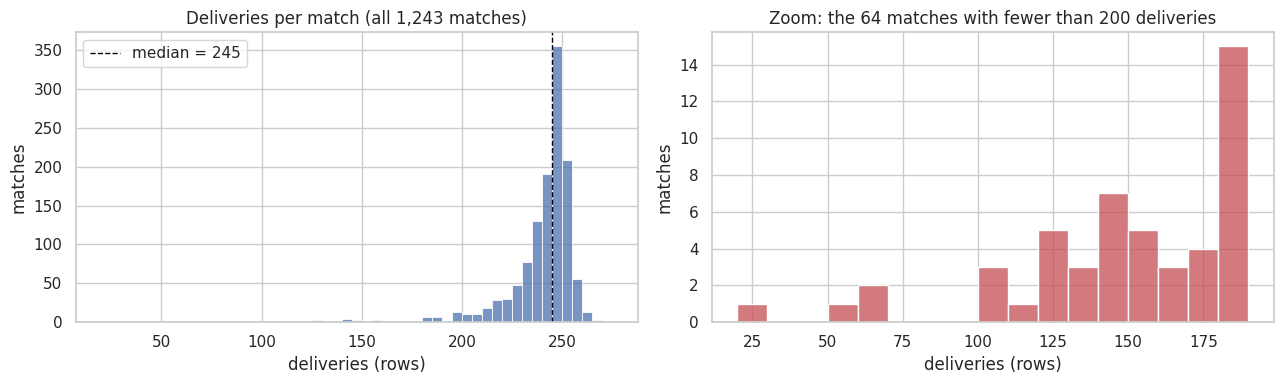

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(per_match, bins=np.arange(20, 280, 5), color="#4C72B0", ax=axes[0])
axes[0].axvline(per_match.median(), color="black", ls="--", lw=1, label=f"median = {per_match.median():.0f}")
axes[0].set(title=f"Deliveries per match (all {len(per_match):,} matches)", xlabel="deliveries (rows)", ylabel="matches")
axes[0].legend()

short = per_match[per_match < 200]
sns.histplot(short, bins=np.arange(20, 200, 10), color="#C44E52", ax=axes[1])
axes[1].set(title=f"Zoom: the {len(short)} matches with fewer than 200 deliveries", xlabel="deliveries (rows)", ylabel="matches")

plt.tight_layout()
plt.show()

In [18]:
is_illegal = df["wides"].notna() | df["noballs"].notna()        # wides and no-balls are not legal deliveries (see section 6)
legal = (~is_illegal).groupby([df["match_id"], df["innings"]]).sum().unstack(fill_value=0)     # legal balls per innings
inn1 = df[df["innings"] == 1].drop_duplicates("match_id").set_index("match_id")

def as_overs(balls):                  # 61 legal balls -> "10.1" overs
    return f"{balls // 6}.{balls % 6}"

lowest = per_match.nsmallest(12).index
low = pd.DataFrame({
    "deliveries": per_match[lowest],
    "innings_recorded": innings_per_match[lowest],
    "inn1_overs": legal.loc[lowest, 1].map(as_overs),
    "inn2_overs": legal.loc[lowest, 2].map(as_overs),
})
low = (
    low.join(match_level.set_index("match_id")[["season", "start_date"]])
       .join(inn1[["batting_team", "bowling_team"]].rename(columns={"batting_team": "batted_first", "bowling_team": "opponent"}))
)
low

,deliveries,innings_recorded,inn1_overs,inn2_overs,season,start_date,batted_first,opponent
match_id,,,,,,,,
1527685,22,1,3.4,0.0,2026,2026-04-06,Kolkata Knight Riders,Punjab Kings
1178424,51,2,5.0,3.2,2019,2019-04-30,Royal Challengers Bangalore,Rajasthan Royals
501265,63,1,10.1,0.0,2011,2011-05-21,Delhi Daredevils,Pune Warriors
1473495,63,1,10.1,0.0,2025,2025-05-08,Punjab Kings,Delhi Capitals
598068,100,2,8.0,8.0,2013,2013-05-18,Royal Challengers Bangalore,Chennai Super Kings
829807,106,2,11.0,5.5,2015,2015-05-15,Sunrisers Hyderabad,Royal Challengers Bangalore
392183,108,2,12.0,4.5,2009,2009-04-19,Kings XI Punjab,Delhi Daredevils
1359519,118,1,19.2,0.0,2023,2023-05-03,Lucknow Super Giants,Chennai Super Kings
336022,123,2,11.0,8.0,2007/08,2008-05-17,Delhi Daredevils,Kings XI Punjab


**Reading deliveries per match**

- **Shape of the distribution.** Median 245, mean 237.9, half of all matches between 236 and 249, maximum 269. A complete match is 2 × 120 legal balls plus extras, so roughly 240–250 is the norm.
- **Most of the left tail is normal.** A chase ends as soon as the target is passed, so a second innings can legitimately stop early: 64 matches (5 %) have fewer than 200 deliveries, and a slope of matches runs from about 180 up to 235. That alone is not an anomaly.

**The true low-count outliers** sit far left of that slope, with a visible gap after the fourth (63 → 100). All four stopped part-way — with no second innings or a very short one:

| match_id | date | teams (batted first v opponent) | deliveries | what the data show |
|---|---|---|---|---|
| **1527685** | 2026-04-06 | Kolkata Knight Riders v Punjab Kings | **22** | one innings only, ended at 3.4 overs — the lowest in the file |
| **1178424** | 2019-04-30 | Royal Challengers Bangalore v Rajasthan Royals | **51** | both innings present, 5.0 overs + 3.2 overs → a reduced-overs match |
| **501265** | 2011-05-21 | Delhi Daredevils v Pune Warriors | **63** | one innings only, ended at 10.1 overs |
| **1473495** | 2025-05-08 | Punjab Kings v Delhi Capitals | **63** | one innings only, ended at 10.1 overs |

- **Next tier (100–130 deliveries):** reduced-over or curtailed matches — e.g. 598068 (8.0 + 8.0 overs) and 829803 (10.0 + 10.0) — plus single-innings matches where the second innings never started (1359519: first innings 19.2 overs; 1473492: 20.0 overs). Six matches in all have only one innings recorded: 501265, 829763, 1359519, 1473492, 1473495 and 1527685.
- **Nothing here points to a data error.** Each looks like a real match that was curtailed (weather and similar reasons are the usual causes), but the file itself does not say why; the result and any reduced-overs method live in the info files. Conclusion deferred.
- **The high end is mostly super overs.** Innings 3–6 exist: 16 matches have a super over — 15 with one (innings 3 and 4) and one, 1216517 (Mumbai Indians v Kings XI Punjab, 2020-10-18), with a second (innings 5 and 6). All 16 sit at 251–269 deliveries, the top of the distribution (though heavy extras alone can reach 265 without one). Per the Cricsheet README, any innings after the second in a T20 is a super over, so they need an explicit decision whenever per-match or per-innings totals are computed.

## 6 · `ball` vs `actual_delivery`

In [19]:
bd = df[["match_id", "innings", "ball", "actual_delivery", "wides", "noballs"]].copy()      # throw-away working copy
bd["over"] = np.floor(bd["ball"]).astype(int)
bd["differ"] = bd["ball"] != bd["actual_delivery"]
bd["illegal"] = bd["wides"].notna() | bd["noballs"].notna()                                  # a wide or a no-ball

print(f"rows where ball != actual_delivery: {bd['differ'].sum():,} of {len(bd):,}  ({bd['differ'].mean():.2%})")
print("rows where the *over* part differs:", int((np.floor(bd['actual_delivery']).astype(int) != bd['over']).sum()))
print(f"wides: {df['wides'].notna().sum():,}   no-balls: {df['noballs'].notna().sum():,}   deliveries that are both: {(df['wides'].notna() & df['noballs'].notna()).sum()}")

rows where ball != actual_delivery: 35,647 of 295,732  (12.05%)
rows where the *over* part differs: 0
wides: 9,876   no-balls: 1,226   deliveries that are both: 0


Two example overs show what is going on — compare the two columns row by row. First, an over containing a wide:

In [20]:
cols = ["ball", "actual_delivery", "wides", "noballs", "runs_off_bat", "extras"]
w = bd.loc[bd.index[bd["wides"].notna()][0]]
df.loc[(bd["match_id"] == w["match_id"]) & (bd["innings"] == w["innings"]) & (bd["over"] == w["over"]), cols]       # first over in the file with a wide

,ball,actual_delivery,wides,noballs,runs_off_bat,extras
0,0.1,0.1,NaN,NaN,0,0
1,0.2,0.2,NaN,NaN,0,0
2,0.3,0.3,NaN,NaN,4,0
3,0.4,0.4,NaN,NaN,0,0
4,0.5,0.5,2.0,NaN,0,2
5,0.6,0.5,NaN,NaN,0,0
6,0.7,0.6,NaN,NaN,0,1


And the first over in the file containing a no-ball:

In [21]:
n = bd.loc[bd.index[bd["noballs"].notna()][0]]
df.loc[(bd["match_id"] == n["match_id"]) & (bd["innings"] == n["innings"]) & (bd["over"] == n["over"]), cols]       # first over in the file with a no-ball

,ball,actual_delivery,wides,noballs,runs_off_bat,extras
7,1.1,1.1,NaN,NaN,1,0
8,1.2,1.2,NaN,NaN,4,0
9,1.3,1.3,NaN,1.0,0,1
10,1.4,1.3,NaN,NaN,6,0
11,1.5,1.4,NaN,NaN,0,0
12,1.6,1.5,NaN,NaN,0,0
13,1.7,1.6,NaN,NaN,4,0


Hypothesis from those examples, tested on **every** row below:
- `ball` = position in the over counting *every* delivery (wides and no-balls included);
- `actual_delivery` = number of *legal* deliveries already bowled in the over, plus 1.

In [22]:
key = [bd["match_id"], bd["innings"], bd["over"]]
illegal_i = bd["illegal"].astype(int)
bd["illegal_before"] = illegal_i.groupby(key, sort=False).cumsum() - illegal_i              # wides/no-balls earlier in the same over
bd["legal_before"] = (1 - illegal_i).groupby(key, sort=False).cumsum() - (1 - illegal_i)    # legal balls earlier in the same over

rule_a = bd["differ"] == (bd["illegal_before"] > 0)                       # the columns differ exactly when a wide/no-ball came earlier in the over
position = np.rint((bd["actual_delivery"] - bd["over"]) * 10).astype(int)
rule_b = position == bd["legal_before"] + 1                               # actual_delivery's decimal digit = legal balls so far + 1

print("rule A (differ <=> a wide/no-ball earlier in the same over):  exceptions =", int((~rule_a).sum()))
print("rule B (actual_delivery = legal balls so far in the over + 1): exceptions =", int((~rule_b).sum()))

overs_total = bd.groupby(["match_id", "innings", "over"]).ngroups
overs_with_extra = bd[bd["illegal"]].groupby(["match_id", "innings", "over"]).ngroups
print(f"overs containing at least one wide/no-ball: {overs_with_extra:,} of {overs_total:,} ({overs_with_extra / overs_total:.1%})")

pd.crosstab(
    bd["illegal"].map({False: "legal delivery", True: "wide / no-ball"}).rename("delivery type"),
    bd["differ"].map({False: "equal", True: "differ"}).rename("ball vs actual_delivery"),
    margins=True,
)

rule A (differ <=> a wide/no-ball earlier in the same over):  exceptions = 0
rule B (actual_delivery = legal balls so far in the over + 1): exceptions = 0
overs containing at least one wide/no-ball: 9,164 of 47,790 (19.2%)


ball vs actual_delivery,differ,equal,All
delivery type,,,
legal delivery,33709,250921,284630
wide / no-ball,1938,9164,11102
All,35647,260085,295732


**Reading `ball` vs `actual_delivery`**

**How often:** they differ on 35,647 of 295,732 deliveries (12.05 %). They never differ in the *over* part — only in the delivery number inside the over.

**Why — a rule with zero exceptions across all 295,732 rows:**
- `ball` is the position of the delivery in the over, **counting every delivery**, wides and no-balls included. An over with one wide therefore runs to `x.7`, an over with two extra deliveries to `x.8`, and so on (the maximum here is `x.11`).
- `actual_delivery` is the number of **legal** deliveries already bowled in the over, plus 1. A wide or no-ball does not use up one of the six, so it takes the number of the legal ball it precedes, and the re-bowled ball then repeats that number (in the first example the wide at `0.5` and the legal ball after it are both `0.5`).
- So the two columns are identical until the first wide/no-ball of an over, still equal on that delivery itself, and different on every later delivery of that over. 9,164 of 47,790 overs (19.2 %) contain at least one wide/no-ball. The crosstab splits the rows accordingly: 9,164 wide/no-ball deliveries still agree (the first one of each over), while 33,709 legal deliveries and 1,938 further wides/no-balls differ — together the 35,647.

**Which to use later:**
- Over-level work (powerplay, middle overs, death overs): either column — the over part is identical.
- "Which ball of the over" and legal balls bowled/faced: `actual_delivery` (or simply count the rows that are not wides/no-balls).
- A unique, ordered delivery id inside an innings: `ball` — but **only as text, or as an (over, ball-in-over) pair of integers**. As a float it is unreliable; the next cells show why.

In [23]:
# The same column read again as text (a diagnostic read — df is untouched) to see what the float representation loses.
ball_text = pd.read_csv(DATA, usecols=["ball"], dtype={"ball": str})["ball"]
delivery_no = ball_text.str.split(".").str[1]

print("ball labels with a 2-digit delivery number (an over with 10+ deliveries):", int((delivery_no.str.len() > 1).sum()))
print("  by delivery number:", delivery_no[delivery_no.str.len() > 1].value_counts().to_dict())
print("duplicate (match_id, innings, ball) keys — ball as float:", int(df.duplicated(["match_id", "innings", "ball"]).sum()),
      "| ball as text:", int(pd.DataFrame({"m": df["match_id"], "i": df["innings"], "b": ball_text}).duplicated().sum()))

collisions = df.loc[df.duplicated(["match_id", "innings", "ball"], keep=False), ["match_id", "innings", "ball"]].assign(ball_as_text=ball_text)
collisions.head(6)      # pairs that the float representation merges

ball labels with a 2-digit delivery number (an over with 10+ deliveries): 49
  by delivery number: {'10': 42, '11': 7}
duplicate (match_id, innings, ball) keys — ball as float: 42 | ball as text: 0


,match_id,innings,ball,ball_as_text
3706,1082606,2,2.1,2.1
3715,1082606,2,2.1,2.10
49890,1216522,2,8.1,8.1
49899,1216522,2,8.1,8.10
59894,1254069,2,10.1,10.1
59903,1254069,2,10.1,10.10


In [24]:
# Row order, checked using the text labels: is the file in delivery order, and are matches in date/id order?
over_no = ball_text.str.split(".").str[0].astype(int)
seq = over_no * 100 + delivery_no.astype(int)                              # (over, delivery-in-over) as one sortable integer
block = df.groupby(["match_id", "innings"], sort=False).ngroup()
print("deliveries strictly increasing within every innings:", bool((seq.groupby(block).diff().dropna() > 0).all()))

in_file_order = match_level.assign(date=pd.to_datetime(match_level["start_date"]))      # one row per match, in file order
print("matches appear in start_date order in the file:", in_file_order["date"].is_monotonic_increasing,
      "| in match_id order:", in_file_order["match_id"].is_monotonic_increasing)

deliveries strictly increasing within every innings: True
matches appear in start_date order in the file: False | in match_id order: False


In [25]:
# Overs with a 7th LEGAL delivery (the odd 10.7 / 11.7 / 18.7 values in actual_delivery).
over_key = [bd["match_id"], bd["innings"], bd["over"]]
legal_in_over = (~bd["illegal"]).groupby(over_key).sum().rename("legal_balls")
extra_balls_in_over = bd["illegal"].groupby(over_key).sum().rename("wides_noballs")
seven = pd.concat([legal_in_over, extra_balls_in_over], axis=1).query("legal_balls > 6").reset_index()
seven.merge(match_level[["match_id", "season", "start_date"]], on="match_id")

,match_id,innings,over,legal_balls,wides_noballs,season,start_date
0,335994,2,10,7,1,2007/08,2008-04-27
1,392198,2,10,7,0,2009,2009-04-28
2,419155,1,18,7,2,2009/10,2010-04-15
3,1136564,2,11,7,0,2018,2018-04-09


**Hazards found**

1. **`ball` as `float64` is lossy.** 42 deliveries are the 10th ball of an over (`'0.10'`, `'19.10'`, …) and 7 are the 11th. As floats, `x.10` becomes `x.1` — **identical to the first ball of that over** (42 duplicate keys in the first table above; zero when `ball` is text) — and `x.11` sorts *before* `x.2`. Sorting or joining on the float `ball` would therefore mis-order or merge real deliveries.
2. **`actual_delivery` is not a unique key either:** a wide and the legal ball after it share a value. It describes legal-ball position, not identity.
3. **Four overs contain a 7th legal delivery** (last table: matches 335994, 392198, 419155 and 1136564), which is why `actual_delivery` has 123 distinct values rather than 120. Seven-ball overs do occur in real cricket when an umpire miscounts, so these may be genuine, but nothing in this file confirms it. Noted, not fixed.
4. **File order.** Inside an innings the rows are in delivery order, but the matches themselves are not sorted by date or by `match_id` across the file — so any window function (`LAG`/`LEAD`, running totals) must sort explicitly.

## 7 · Summary: what needs standardizing before real analysis

**Headlines.** (1) The numeric columns are internally consistent; the work is in categorical labels and in how some columns are encoded. (2) Season labels, team names and venues each hide the same mixture — part pure formatting (a rule can fix it), part genuine renames (only a hand-made mapping can): 19 season labels need a year mapping, 19 team strings are 15 franchises, 60 venue strings are roughly 36 grounds. (3) `ball` cannot safely be a float. (4) Only **two** columns are truly empty, not four. (5) Short matches and super overs are real and need a scope decision, not a fix.

The list is split by **kind**, because the kind decides how each item gets fixed: formatting problems yield to a rule; genuine renames need a mapping plus a decision about what to analyse by; semantic points need a definition rather than a transformation.

| # | Field(s) | What was seen | Kind | Likely handling in the cleaning session |
|---|---|---|---|---|
| 1 | `season` | 3 split-year labels (`2007/08`, `2009/10`, `2020/21`) among 16 plain years; neither first-four-characters nor last-two-digits parsing is right for all three | Formatting inconsistency (needs a mapping) | Derive the tournament year from `start_date` (19 labels ↔ 19 years) |
| 2 | `batting_team`, `bowling_team` | Delhi Daredevils → Delhi Capitals, Kings XI Punjab → Punjab Kings, Royal Challengers Bangalore → Bengaluru | **Genuine renames** (3) | Mapping table; decide franchise key vs name-at-the-time |
| 3 | same | `Rising Pune Supergiants` / `Rising Pune Supergiant` | **Spelling variant** (1) | Unify the string |
| 4 | same | Deccan Chargers / Sunrisers Hyderabad, Pune Warriors / Rising Pune Supergiant, Gujarat Lions / Gujarat Titans | Look-alikes — different franchises | Keep separate unless a question says otherwise |
| 5 | `venue` | 60 strings → 41 under a mechanical rule: city/locality suffix present or not, punctuation (`M` vs `M.`) | **Formatting inconsistency** (19 surplus strings) | Rule-based normalisation, reviewed by hand |
| 6 | `venue` | 5 grounds under two names (Feroz Shah Kotla / Arun Jaitley; PCA Stadium / PCA IS Bindra; Sardar Patel / Narendra Modi; Subrata Roy Sahara / MCA Stadium; Sheikh Zayed / Zayed Cricket Stadium) | **Genuine renames** (5) | Hand-built mapping to one canonical ground, plus city and country; about 36 grounds expected |
| 7 | `start_date` | ISO text | Type | Convert to datetime |
| 8 | `ball`, `actual_delivery` | float64; `x.10` collapses onto `x.1` (42 keys), `x.11` mis-sorts (7) | Encoding | Keep `ball` as text and/or split into integer over + ball-in-over; use `actual_delivery` for legal-ball position |
| 9 | `wides`, `noballs`, `byes`, `legbyes`, `penalty`; `wicket_type`, `player_dismissed`, `fielder_1–2` | Blank = event did not happen (verified against `extras` and each other) | Structural blanks | Fill counts with 0 and cast to int; keep dismissal columns blank-as-none, or add an `is_wicket` flag |
| 10 | `non_boundary` | `object` (`True`/blank); all 29 filled rows have `runs_off_bat` of 4 or 6, which suggests it marks 4s/6s that were not boundaries | Encoding + meaning | Confirm in Cricsheet's format notes, cast to bool, exclude flagged rows when counting boundaries |
| 11 | `other_wicket_type`, `other_player_dismissed` | 100 % empty | Truly empty | Candidates to drop |
| 12 | `penalty` (2 rows), `fielder_3` (13) | Print as 100.00 % missing but hold real events | Near-empty | Keep unless a deliberate decision says otherwise |
| 13 | `innings` | Values 3–6 are super overs: 16 matches, one with two | Scope | Flag; exclude from innings/match totals unless a question needs them |
| 14 | whole matches | 6 single-innings matches; reduced-over matches; low outliers with 22 / 51 / 63 / 63 deliveries | Scope | Flag using result/method from the info files before excluding anything |
| 15 | `wicket_type` | `run out`, `retired hurt`, `retired out`, `obstructing the field` are not bowler wickets | Definition | Decide per question what counts as a wicket |
| 16 | `actual_delivery` | 4 overs with a 7th legal delivery | Anomaly | Flag; check against the info files / scorecards |
| 17 | row order | Delivery order is right within an innings, but matches are not sorted by date or id | Order | Sort explicitly before `LAG`/`LEAD` or running totals |
| 18 | `actual_delivery`, `non_boundary`, `fielder_1–3` | Not in the bundled README's list of headers | Documentation gap | Confirm definitions on Cricsheet's CSV format page |

## 8 · Proof that nothing was changed

In [26]:
assert int(pd.util.hash_pandas_object(df, index=True).sum()) == LOAD_FINGERPRINT, "df was modified somewhere in this notebook"
print("df is identical to what was loaded (row-hash fingerprint matches). shape:", df.shape)

df is identical to what was loaded (row-hash fingerprint matches). shape: (295732, 27)


**Deliberately not covered in this session:** the per-match info files; consistency of player names across `striker`, `non_striker`, `bowler`, `player_dismissed` and `fielder_*`; cross-checks between ball-by-ball totals and match results.

**Next:** profile the info files, then a separate cleaning session that works through the worklist in section 7.